# Animal Image Classifier — MobileNetV2 Transfer Learning

Notebook นี้ใช้เฉพาะโมเดล **MobileNetV2 Transfer Learning** สำหรับจำแนกภาพ Bird, Cat และ Dog ตัดส่วน Custom CNN ออกแล้ว


---

## MobileNetV2 Transfer Learning

ส่วนนี้ใช้ MobileNetV2 ที่ฝึกจาก ImageNet เป็นฐาน แล้วฝึกชั้นจำแนกสำหรับ Bird, Cat และ Dog พร้อมประเมินผลบนชุดทดสอบและบันทึกโมเดล

## 2. แหล่งที่มาและอธิบายชุดข้อมูล

คาดว่าโฟลเดอร์ข้อมูลจัดแบบ `flow_from_directory` ตามโค้ดเดิม:

```text
train_images/
  bird/
  cat/
  dog/
test_images/
  bird/
  cat/
  dog/
```

ตามข้อมูลที่ผู้ใช้แจ้ง: มีภาพชุดฝึกเดิมคลาสละ 1,600 ภาพ (รวม 4,800 ภาพ) และชุดทดสอบคลาสละ 400 ภาพ (รวม 1,200 ภาพ) อย่างไรก็ตาม จำนวนจริงจะถูกตรวจนับจากโฟลเดอร์โดยโค้ดด้านล่าง

- ชุดฝึกเดิม: 4,800 ภาพ
- ชุดทดสอบ: 1,200 ภาพ
- ภายใน notebook นี้จะแบ่ง `train_images/` เป็น train 80% และ validation 20% โดยประมาณ (train 1,280 ภาพ/คลาส, validation 320 ภาพ/คลาส หากมีจำนวนคลาสละ 1,600 ภาพ)
- `test_images/` จะไม่ถูกใช้ระหว่าง fit หรือเลือกโมเดล


## 3. สำรวจและเตรียมข้อมูล

ภาพถูกปรับเป็น RGB และขนาด 224×224 พิกเซลตาม `config.py` จากนั้นปรับค่าสีให้อยู่ในช่วง 0–1 ตามแนวทางใน `dataset.py` และ `app.py` ชุดฝึกใช้ Data Augmentation แบบหมุน ขยับแนวกว้าง/สูง และพลิกแนวนอน เพื่อเพิ่มความหลากหลาย ส่วน validation และ test ไม่ใช้ augmentation

> หมายเหตุ: โมเดล MobileNetV2 ที่ใช้ pretrained weights มักมีวิธี preprocess เฉพาะของตนเอง แต่โค้ดเดิมใช้การหารด้วย 255 ดังนั้น notebook นี้คง preprocessing ให้สอดคล้องกับโค้ดเดิมและเว็บแอปที่แนบมา


In [1]:
# ติดตั้ง/นำเข้าไลบรารี (หากรันในสภาพแวดล้อมใหม่ ให้รัน: %pip install tensorflow numpy matplotlib scikit-learn pillow)
from pathlib import Path
import os, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 15
TRAIN_DIR = Path("train_images")
TEST_DIR = Path("test_images")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

if not TRAIN_DIR.exists() or not TEST_DIR.exists():
    raise FileNotFoundError(
        "ไม่พบ train_images/ หรือ test_images/ กรุณารัน notebook จากโฟลเดอร์หลักของโปรเจกต์ "
        "ที่มีโฟลเดอร์ข้อมูลเหล่านี้"
    )

print("TensorFlow:", tf.__version__)
print("Train folder:", TRAIN_DIR.resolve())
print("Test folder:", TEST_DIR.resolve())


TensorFlow: 2.22.0-rc0
Train folder: D:\uni\Year 3.1\intro data\DataSciProject\Animal_image_classifier\train_images
Test folder: D:\uni\Year 3.1\intro data\DataSciProject\Animal_image_classifier\test_images


Number of images in train_images: {'bird': 1600, 'cat': 1600, 'dog': 1600} Total = 4800
Number of images in test_images: {'bird': 400, 'cat': 400, 'dog': 400} Total = 1200


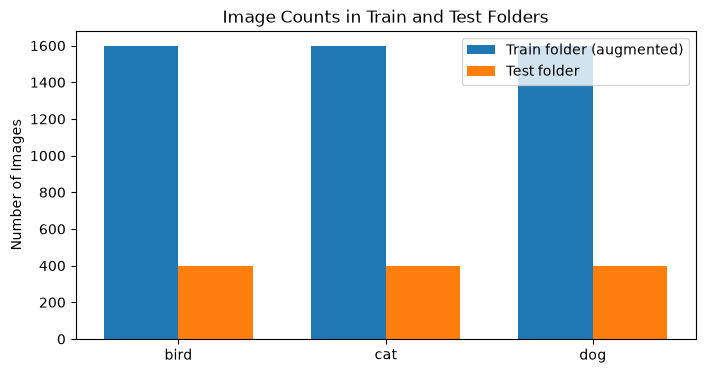

In [15]:
# ตรวจนับจำนวนภาพจากไฟล์จริงในแต่ละคลาส
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASS_NAMES = ["bird", "cat", "dog"]  # เรียงตามชื่อโฟลเดอร์แบบเดียวกับ flow_from_directory เดิม

def count_images(root):
    counts = {}
    for class_name in CLASS_NAMES:
        folder = root / class_name
        if not folder.exists():
            raise FileNotFoundError(f"Folder not found: {folder}")
        counts[class_name] = sum(1 for p in folder.rglob("*") if p.suffix.lower() in IMG_EXTS)
    return counts

train_counts = count_images(TRAIN_DIR)
test_counts = count_images(TEST_DIR)
print("Number of images in train_images:", train_counts, "Total =", sum(train_counts.values()))
print("Number of images in test_images:", test_counts, "Total =", sum(test_counts.values()))

plt.figure(figsize=(8, 4))
x = np.arange(len(CLASS_NAMES))
plt.bar(x - 0.18, [train_counts[c] for c in CLASS_NAMES], width=0.36, label="Train folder (augmented)")
plt.bar(x + 0.18, [test_counts[c] for c in CLASS_NAMES], width=0.36, label="Test folder")
plt.xticks(x, CLASS_NAMES)
plt.ylabel("Number of Images")
plt.title("Image Counts in Train and Test Folders")
plt.legend()
plt.show()


### แบ่งข้อมูลและเตรียมภาพ

ใช้เฉพาะ `train_images/` เพื่อสร้างชุดฝึกและ validation โดยแบ่ง 80:20 ภายในโฟลเดอร์นี้ ส่วน `test_images/` แยกเก็บไว้สำหรับประเมินขั้นสุดท้ายเท่านั้น

In [3]:
# แบ่งเฉพาะ train_images เป็น train 80% และ validation 20%
# test_images ไม่ถูกใช้ในขั้นตอนนี้ และจะใช้เฉพาะการประเมินสุดท้าย
datagen_args = dict(
    rescale=1./255,
    validation_split=0.2
)
train_datagen = keras.preprocessing.image.ImageDataGenerator(
    **datagen_args,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)
valid_datagen = keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)
test_datagen = keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    str(TRAIN_DIR), target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    classes=CLASS_NAMES, class_mode="categorical", subset="training",
    shuffle=True, seed=SEED
)
val_gen = valid_datagen.flow_from_directory(
    str(TRAIN_DIR), target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    classes=CLASS_NAMES, class_mode="categorical", subset="validation",
    shuffle=False, seed=SEED
)
test_gen = test_datagen.flow_from_directory(
    str(TEST_DIR), target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    classes=CLASS_NAMES, class_mode="categorical", shuffle=False
)

print("Class indices:", train_gen.class_indices)
print("จำนวนภาพ train =", train_gen.samples)
print("จำนวนภาพ validation =", val_gen.samples)
print("จำนวนภาพ test =", test_gen.samples)


Found 3840 images belonging to 3 classes.
Found 960 images belonging to 3 classes.
Found 1200 images belonging to 3 classes.
Class indices: {'bird': 0, 'cat': 1, 'dog': 2}
จำนวนภาพ train = 3840
จำนวนภาพ validation = 960
จำนวนภาพ test = 1200


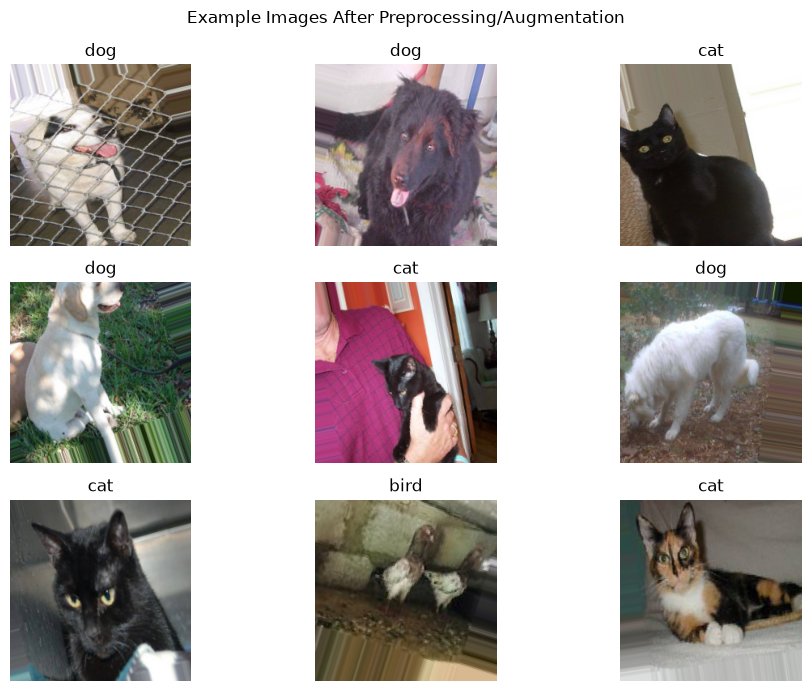

In [12]:
# ดูตัวอย่างภาพหลังการเตรียมข้อมูล
images, labels = next(train_gen)
plt.figure(figsize=(10, 7))
for i in range(min(9, len(images))):
    ax = plt.subplot(3, 3, i + 1)
    ax.imshow(np.clip(images[i], 0, 1))
    ax.set_title(CLASS_NAMES[int(np.argmax(labels[i]))])
    ax.axis("off")
plt.suptitle("Example Images After Preprocessing/Augmentation")
plt.tight_layout()
plt.show()


## 4. ฝึกแบบจำลอง: Transfer Learning ด้วย MobileNetV2

เลือก MobileNetV2 เพราะเป็นโครงข่ายที่ผ่านการฝึกกับ ImageNet มาก่อน จึงนำคุณลักษณะภาพที่เรียนรู้มาใช้ต่อได้ โดยแช่แข็งชั้นฐานไว้และเพิ่มชั้นจำแนกสำหรับ 3 คลาส วิธีนี้มักช่วยลดจำนวนพารามิเตอร์ที่ต้องฝึกเมื่อเทียบกับการสร้าง CNN ทั้งหมดจากศูนย์ และสอดคล้องกับ `models.py`/`train.py` ที่แนบมา.

In [5]:
# MobileNetV2 pretrained ImageNet; base model ถูก freeze ตาม models.py
base_model = keras.applications.MobileNetV2(
    weights="imagenet", include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(len(CLASS_NAMES), activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
history = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen
)


Epoch 1/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 104s 793ms/step - accuracy: 0.8521 - loss: 0.4223 - val_accuracy: 0.9625 - val_loss: 0.1393
Epoch 2/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 96s 794ms/step - accuracy: 0.9516 - loss: 0.1599 - val_accuracy: 0.9688 - val_loss: 0.1004
Epoch 3/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 94s 782ms/step - accuracy: 0.9633 - loss: 0.1170 - val_accuracy: 0.9708 - val_loss: 0.0858
Epoch 4/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 93s 769ms/step - accuracy: 0.9633 - loss: 0.1084 - val_accuracy: 0.9708 - val_loss: 0.0778
Epoch 5/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 91s 759ms/step - accuracy: 0.9688 - loss: 0.0945 - val_accuracy: 0.9750 - val_loss: 0.0701
Epoch 6/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 91s 755ms/step - accuracy: 0.9685 - loss: 0.0895 - val_accuracy: 0.9750 - val_loss: 0.0694
Epoch 7/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 92s 765ms/step - accuracy: 0.9727 - loss: 0.0795 - val_accuracy: 0.9771 - val_loss: 0.0680
Epoch 8/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 93s 770ms/step - accuracy: 0.9745 - loss: 

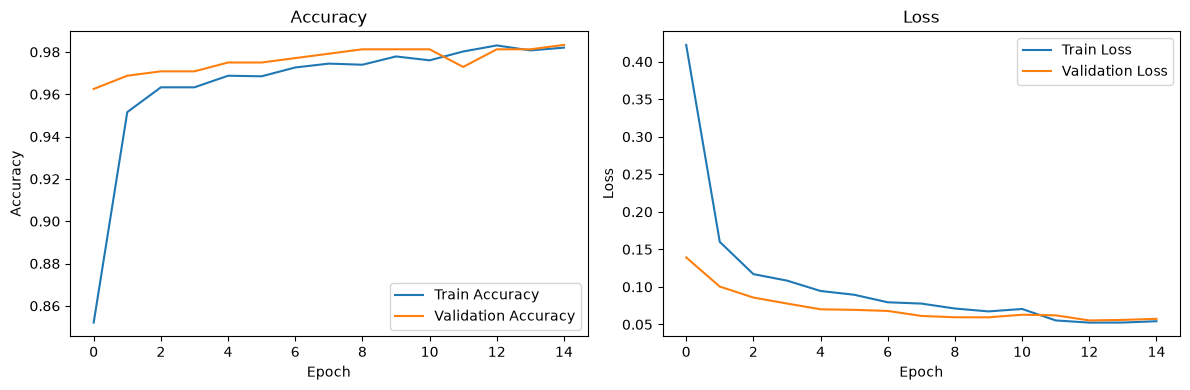

In [16]:
# กราฟผลระหว่างฝึก (ใช้ train/validation เท่านั้น ไม่ใช่ test)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Accuracy")
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Loss")
plt.tight_layout(); plt.show()


## 6. ประเมินผลบนชุดทดสอบและแปลความหมาย

จะรายงาน Accuracy, Precision, Recall และ F1-score รายคลาส พร้อมค่าเฉลี่ย **macro average** ซึ่งคำนวณคะแนนแต่ละคลาสแล้วเฉลี่ยโดยให้น้ำหนักแต่ละคลาสเท่ากัน และ **weighted average** ซึ่งถ่วงน้ำหนักตามจำนวนตัวอย่างในแต่ละคลาส นอกจากนี้จะแสดง confusion matrix เพื่อดูว่าคลาสใดสับสนกัน

- **Precision**: ในภาพที่โมเดลทำนายเป็นคลาสนั้น มีสัดส่วนที่ถูกต้องเท่าใด
- **Recall**: จากภาพจริงของคลาสนั้น โมเดลจำแนกถูกได้กี่ส่วน
- **F1-score**: ค่าเฉลี่ยฮาร์มอนิกระหว่าง Precision และ Recall
- **Accuracy**: สัดส่วนภาพทั้งหมดที่ทำนายถูก

ผลที่ได้ขึ้นอยู่กับการฝึกและข้อมูลจริง ไม่ควรใส่ค่าคาดเดาแทนผลที่รันได้


38/38 ━━━━━━━━━━━━━━━━━━━━ 18s 465ms/step - accuracy: 0.9792 - loss: 0.0617
Test Loss: 0.0617
Test Accuracy: 0.9792
38/38 ━━━━━━━━━━━━━━━━━━━━ 21s 485ms/step

Classification report (รายคลาส + macro avg + weighted avg):
              precision    recall  f1-score   support

        Bird     0.9779    0.9975    0.9876       400
         Cat     0.9896    0.9550    0.9720       400
         Dog     0.9704    0.9850    0.9777       400

    accuracy                         0.9792      1200
   macro avg     0.9793    0.9792    0.9791      1200
weighted avg     0.9793    0.9792    0.9791      1200



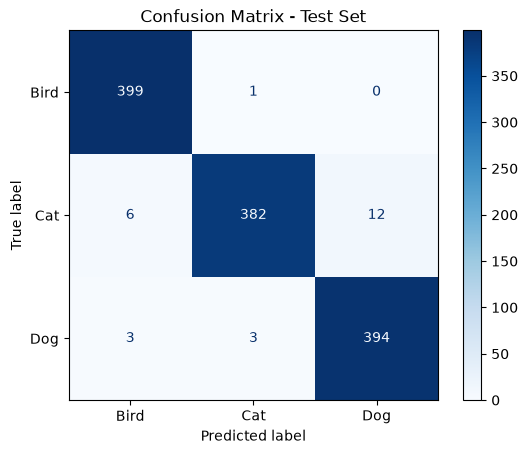

Macro Precision: 0.9793
Macro Recall:    0.9792
Macro F1-score:  0.9791
Weighted F1-score: 0.9791


In [8]:
# ประเมินชุดทดสอบเพียงครั้งเดียว หลังฝึกแบบจำลองเสร็จ
test_gen.reset()
test_loss, test_accuracy = model.evaluate(test_gen, verbose=1)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

test_gen.reset()
probabilities = model.predict(test_gen, verbose=1)
y_pred = np.argmax(probabilities, axis=1)
y_true = test_gen.classes

print("\nClassification report (รายคลาส + macro avg + weighted avg):")
print(classification_report(
    y_true, y_pred, labels=list(range(len(CLASS_NAMES))),
    target_names=[c.title() for c in CLASS_NAMES],
    digits=4, zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[c.title() for c in CLASS_NAMES])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Test Set")
plt.show()

# คำนวณ macro average โดยเฉลี่ย metric ของแต่ละคลาสด้วยน้ำหนักเท่ากัน
report = classification_report(
    y_true, y_pred, labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0
)
print(f"Macro Precision: {report['macro avg']['precision']:.4f}")
print(f"Macro Recall:    {report['macro avg']['recall']:.4f}")
print(f"Macro F1-score:  {report['macro avg']['f1-score']:.4f}")
print(f"Weighted F1-score: {report['weighted avg']['f1-score']:.4f}")


## 7. ตัวอย่างผลทำนายและวิเคราะห์ข้อผิดพลาด

ส่วนนี้จะแสดงตัวอย่างภาพในชุดทดสอบที่โมเดลทำนายผิด พร้อมคลาสจริง คลาสที่ทำนาย และคะแนนความน่าจะเป็นของคลาสที่ทำนาย หากไม่มีตัวอย่างผิด ระบบจะแจ้งให้ทราบ

การดูภาพผิดช่วยสังเกตได้ว่าความสับสนเกิดระหว่างคลาสใด แต่การอธิบายสาเหตุ เช่น ภาพเบลอ แสงน้อย หรือสัตว์มีลักษณะคล้ายกัน ต้องตรวจดูภาพจริงก่อนสรุป


Wrong predictions: 25 out of 1200


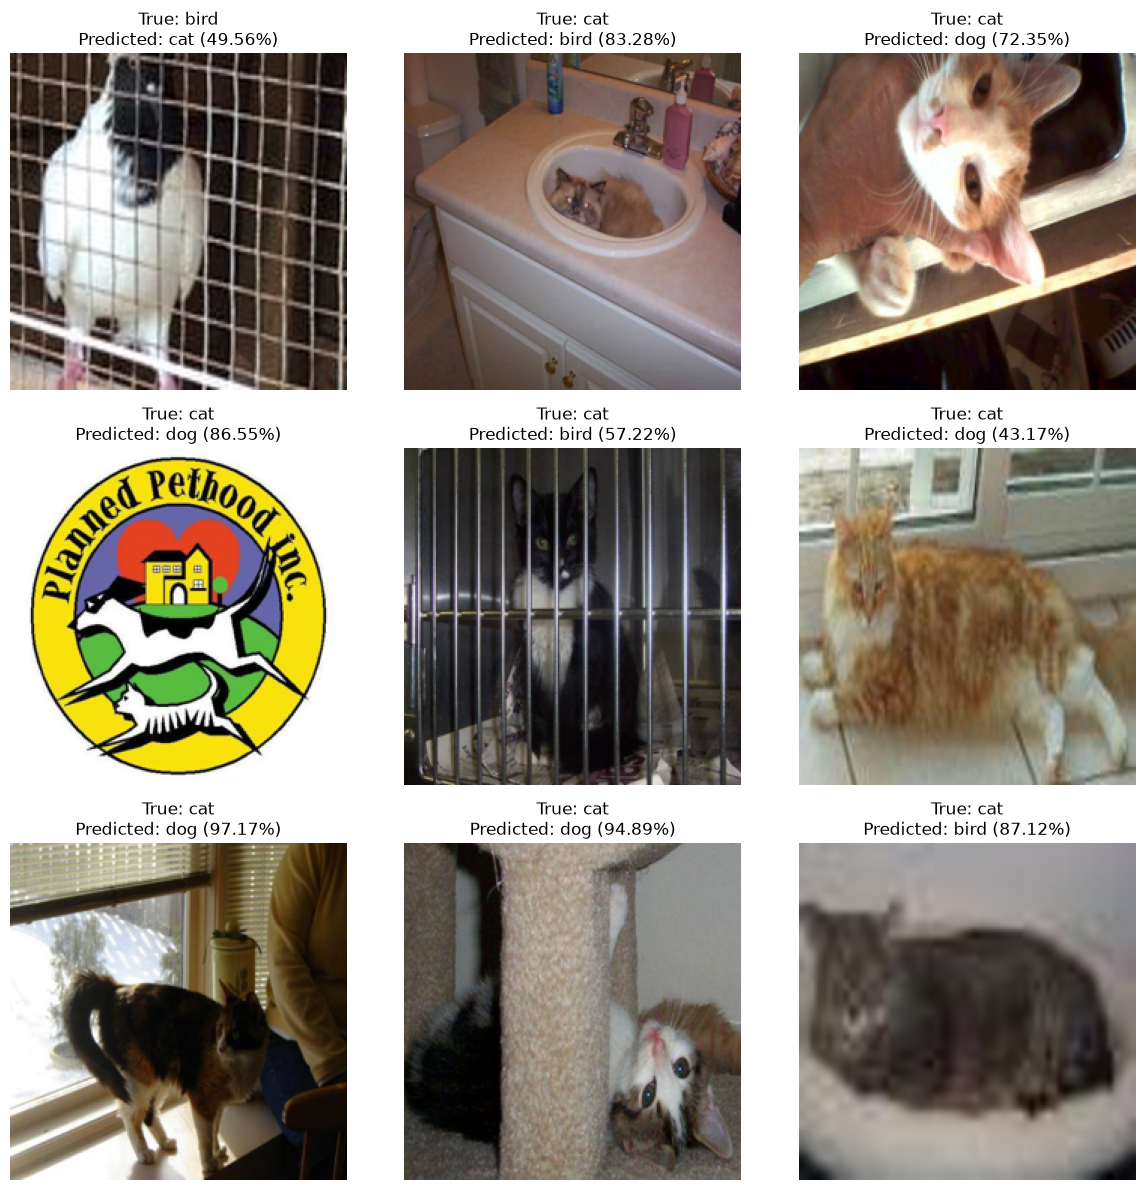


Sample Predictions:
1633803178708_Cocktail Bird for sale.jpg: True=bird, Predicted=bird, Confidence=1.0000
1633803179542_Shamo Rooster for sale.jpg: True=bird, Predicted=bird, Confidence=0.9711
1633803180296_Pigeons for sale.jpg: True=bird, Predicted=bird, Confidence=0.9985
1633803180897_Pigeon for sale.jpg: True=bird, Predicted=bird, Confidence=0.9848
1633803181082_Pigeons for sale.jpg: True=bird, Predicted=bird, Confidence=0.9955
1633803181244_Pigeons for sale.jpg: True=bird, Predicted=bird, Confidence=0.9997
1633803181430_Pigeon for sale.jpg: True=bird, Predicted=bird, Confidence=0.9932
1633803181784_Pigeons for sale.jpg: True=bird, Predicted=bird, Confidence=0.9997
1633803182632_Aseel Rooster for sale.jpg: True=bird, Predicted=bird, Confidence=0.9999
1633803231571_Aseel Rooster for sale.jpg: True=bird, Predicted=bird, Confidence=0.9894


In [17]:
# แสดงตัวอย่างผลทำนายและภาพที่จำแนกผิด
test_paths = test_gen.filepaths
wrong_indices = np.where(y_pred != y_true)[0]
print(f"Wrong predictions: {len(wrong_indices)} out of {len(y_true)}")

if len(wrong_indices) == 0:
    print("No wrong predictions found in the test set")
else:
    n_show = min(9, len(wrong_indices))
    plt.figure(figsize=(12, 4 * ((n_show + 2) // 3)))
    for plot_i, idx in enumerate(wrong_indices[:n_show], start=1):
        img = Image.open(test_paths[idx]).convert("RGB").resize(IMG_SIZE)
        pred_class = CLASS_NAMES[y_pred[idx]]
        true_class = CLASS_NAMES[y_true[idx]]
        confidence = float(probabilities[idx][y_pred[idx]])
        ax = plt.subplot((n_show + 2) // 3, 3, plot_i)
        ax.imshow(img)
        ax.set_title(f"True: {true_class}\nPredicted: {pred_class} ({confidence:.2%})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# ตัวอย่างภาพที่ทำนายถูก/ทุกคลาสเพื่อดูผลคะแนน
print("\nSample Predictions:")
for i in range(min(10, len(y_true))):
    print(f"{Path(test_paths[i]).name}: True={CLASS_NAMES[y_true[i]]}, "
          f"Predicted={CLASS_NAMES[y_pred[i]]}, "
          f"Confidence={probabilities[i][y_pred[i]]:.4f}")


## 8. บันทึกแบบจำลองสำหรับเว็บแอป

โมเดลจะถูกบันทึกในโฟลเดอร์ `model/` เป็นไฟล์ `.h5` สำหรับนำไปใช้กับ `app.py` ที่แนบมา โดย notebook ของ Transfer Learning จะบันทึกเป็น `model/transfer_model.h5` ตามชื่อที่เว็บแอปคาดหวัง ส่วน Custom CNN จะบันทึกเป็น `model/custom_cnn_model.h5`.

> `app.py` ที่ได้รับโหลด `model/transfer_model.h5` โดยตรง ดังนั้นหากต้องใช้ Custom CNN ในเว็บแอป จะต้องปรับ `app.py` ให้โหลดโมเดล Custom CNN แทน และตรวจสอบ preprocessing ให้ตรงกัน


In [10]:
model_path = MODEL_DIR / "transfer_model.h5"
model.save(model_path)
print("บันทึกโมเดลแล้ว:", model_path.resolve())
print("ไฟล์นี้ตรงกับพาธที่ app.py โหลด: model/transfer_model.h5")

บันทึกโมเดลแล้ว: D:\uni\Year 3.1\intro data\DataSciProject\Animal_image_classifier\model\transfer_model.h5
ไฟล์นี้ตรงกับพาธที่ app.py โหลด: model/transfer_model.h5
